<div dir="rtl" align="right">

# آزمون فرض نسبت دو نمونه‌ای

## آسانسور و بازسازی

1. تعداد **موفقیت‌ها** در هر گروه
2. تعداد **کل نمونه‌ها** در هر گروه
3. **نسبت بازسازی** در هر گروه
4. بررسی شرط **نرمال بودن تقریبی**
5. **آزمون Z دو نمونه‌ای** (Two-Sample Z-Test)
6. رسم نمودار
7. محدوده محور عمودی
8. نمایش مقدار درصد روی ستون‌ها

</div>

Initial rows: 1000000
Rows after removing missing values: 381932

Group information:
Elevator: n=244516, success=81372, p=0.333
No Elevator: n=137416, success=59420, p=0.432

Checking conditions for normal approximation:
Elevator: n*p = 81372.0, n*(1-p) = 163144.0
No Elevator: n*p = 59420.0, n*(1-p) = 77996.0

Conditions are met.

Two-Sample Proportion Z-Test
H0: p_elevator = p_no_elevator
H1: p_elevator != p_no_elevator
z-statistic: -61.248452481793564
p-value: 0.0

Reject H0
There is a significant difference between the two proportions.


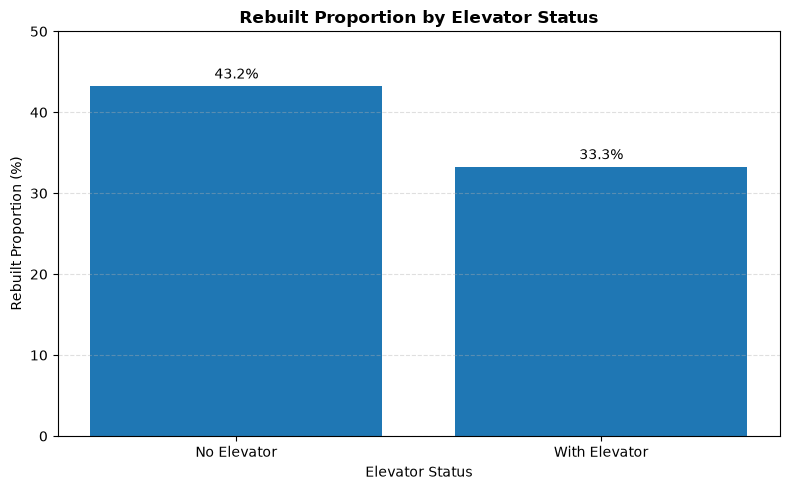

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

file_path = "C:/Users/Asus/Desktop/final_data.csv"
df = pd.read_csv(
    file_path,
    usecols=["has_elevator", "is_rebuilt"])

print("Initial rows:", len(df))
df = df.dropna(
    subset=["has_elevator", "is_rebuilt"])

print("Rows after removing missing values:", len(df))


elevator_success = len(
    df[
        (df["has_elevator"] == 1) &
        (df["is_rebuilt"] == 1)])


no_elevator_success = len(
    df[
        (df["has_elevator"] == 0) &
        (df["is_rebuilt"] == 1)])


n_elevator = len(
    df[df["has_elevator"] == 1])


n_no_elevator = len(
    df[df["has_elevator"] == 0])

# نسبت بازسازی در هر گروه
p_elevator = elevator_success / n_elevator
p_no_elevator = no_elevator_success / n_no_elevator


print("\nGroup information:")
print(
    f"Elevator: n={n_elevator}, "
    f"success={elevator_success}, "
    f"p={p_elevator:.3f}")


print(
    f"No Elevator: n={n_no_elevator}, "
    f"success={no_elevator_success}, "
    f"p={p_no_elevator:.3f}")


# بررسی شرط نرمال بودن تقریبی
print("\nChecking conditions for normal approximation:")
print(f"Elevator: n*p = "
    f"{n_elevator * p_elevator:.1f}, "
    f"n*(1-p) = "
    f"{n_elevator * (1-p_elevator):.1f}")


print(f"No Elevator: n*p = "
    f"{n_no_elevator * p_no_elevator:.1f}, "
    f"n*(1-p) = "
    f"{n_no_elevator * (1-p_no_elevator):.1f}")

# Two-Sample Z-Test
if (n_elevator * p_elevator >= 5 and
    n_elevator * (1-p_elevator) >= 5 and
    n_no_elevator * p_no_elevator >= 5 and
    n_no_elevator * (1-p_no_elevator) >= 5):

    print("\nConditions are met.")
    z_stat, p_value = proportions_ztest(
        count=[
            elevator_success,
            no_elevator_success],
        nobs=[
            n_elevator,
            n_no_elevator],
        alternative="two-sided")


    print("\nTwo-Sample Proportion Z-Test")
    print("H0: p_elevator = p_no_elevator")
    print("H1: p_elevator != p_no_elevator")
    print("z-statistic:",z_stat)
    print("p-value:",p_value)


    alpha = 0.05


    if p_value < alpha:
        print("\nReject H0")
        print("There is a significant difference "
            "between the two proportions.")

    else:
        print("\nFail to reject H0")
        print("There is no significant difference "
            "between the two proportions.")


else:
    print("\nConditions are not met.")

# رسم نمودار

groups = ["No Elevator","With Elevator"]

proportions = [p_no_elevator * 100,p_elevator * 100]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    groups,
    proportions)


ax.set_title("Rebuilt Proportion by Elevator Status",
    fontsize=12,
    fontweight="bold")

ax.set_xlabel("Elevator Status",
    fontsize=10)


ax.set_ylabel("Rebuilt Proportion (%)",
    fontsize=10)


# محدوده محور عمودی
ax.set_ylim(0,50)

# نمایش مقدار درصد روی ستون‌ها
ax.bar_label(
    bars,
    labels=[f"{p_no_elevator * 100:.1f}%",
        f"{p_elevator * 100:.1f}%"],padding=3)

ax.grid(axis="y",
    linestyle="--",
    alpha=0.4)


plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

# آزمون فرض امتیازی دوم

## Kruskal-Wallis: جهت ساختمان و قیمت

1. محدود کردن **داده‌های پرت** با `IQR`
2. جایگزین کردن مقادیر پرت با **حد مجاز IQR**
3. تعداد نمونه‌ها در هر جهت
4. تشکیل گروه‌ها برای **Kruskal-Wallis**
5. اجرای آزمون **Kruskal-Wallis**
6. مقایسه قیمت ملک بر اساس **جهت ساختمان**
7. رسم نمودار `Median Price by Building Direction`
8. نمایش مقدار **میانه** روی ستون‌ها

</div>

Initial rows: 1000000
Rows after removing missing values: 202871
Rows after handling outliers: 202871

Building direction:
building_direction
south    100670
north     90073
east       7674
west       4454
Name: count, dtype: int64

Kruskal-Wallis test
H statistic: 2829.6358079302295
p-value: 0.0

Reject H0
There is a significant difference between the groups.

Price comparison by building direction:
                     count          mean        median  min           max
building_direction                                                       
south               100670  5.199437e+09  3.800000e+09  0.0  1.328750e+10
north                90073  4.480585e+09  3.200000e+09  0.0  1.328750e+10
east                  7674  3.874512e+09  2.800000e+09  0.0  1.328750e+10
west                  4454  3.868911e+09  2.780000e+09  0.0  1.328750e+10


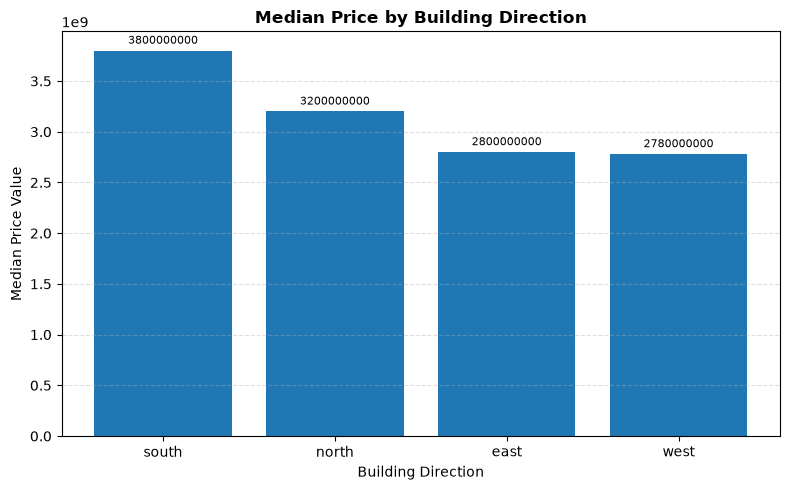

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal

file_path = "C:/Users/Asus/Desktop/final_data.csv"

df = pd.read_csv(file_path, usecols=["price_value", "building_direction"])

print("Initial rows:", len(df))

df = df.dropna(subset=["price_value", "building_direction"])
df["price_value"] = pd.to_numeric(df["price_value"], errors="coerce")
df = df.dropna(subset=["price_value"])

print("Rows after removing missing values:", len(df))

# محدود کردن داده‌های پرت با IQR
Q1 = df["price_value"].quantile(0.25)
Q3 = df["price_value"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# جایگزین کردن مقادیر پرت با حد مجاز IQR
df["price_value"] = df["price_value"].clip(lower=lower, upper=upper)

print("Rows after handling outliers:", len(df))

# تعداد نمونه‌ها در هر جهت
print("\nBuilding direction:")
print(df["building_direction"].value_counts())

# تشکیل گروه‌ها برای Kruskal-Wallis
groups = []
for direction in df["building_direction"].unique():
    group = df.loc[df["building_direction"] == direction, "price_value"]
    groups.append(group)

# اجرای آزمون Kruskal-Wallis
statistic, p_value = kruskal(*groups)

print("\nKruskal-Wallis test")
print("H statistic:", statistic)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nReject H0")
    print("There is a significant difference between the groups.")
else:
    print("\nFail to reject H0")
    print("There is no significant difference between the groups.")

# مقایسه قیمت ملک بر اساس جهت ساختمان
summary = df.groupby("building_direction")["price_value"].agg(
    count="count",
    mean="mean",
    median="median",
    min="min",
    max="max"
).sort_values("median", ascending=False)

print("\nPrice comparison by building direction:")
print(summary)

# رسم نمودار Median Price by Building Direction
directions = summary.index
median_prices = summary["median"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(directions, median_prices)

ax.set_title("Median Price by Building Direction", fontsize=12, fontweight="bold")
ax.set_xlabel("Building Direction", fontsize=10)
ax.set_ylabel("Median Price Value", fontsize=10)

# نمایش مقدار میانه روی ستون‌ها
ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)

ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

<div dir="rtl" align="right">

# آزمون فرض کای دو (Chi-Square Test of Independence)

## نوع ملک و نوع سند

1. خلاصه **نوع ملک**
2. خلاصه **نوع سند**
3. تشکیل **جدول توافقی**
4. اجرای آزمون **Chi-Square**
5. بررسی **شرط آزمون** Chi-Square
6. درصد نوع سند به تفکیک نوع ملک
7. نمودار

</div>

Initial rows: 1000000
Rows after removing missing values: 21975

Property types summary:
property_type
jungle             14584
other               2861
beach               2631
jungle-mountain     1751
mountain             148
Name: count, dtype: int64

Deed types summary:
deed_type
single_page          18598
written_agreement     1563
other                 1449
multi_page             365
Name: count, dtype: int64

Contingency Table (Observed Frequencies):
deed_type        multi_page  other  single_page  written_agreement
property_type                                                     
beach                    43    340         2020                228
jungle                  112    587        13327                558
jungle-mountain          16     88         1541                106
mountain                  7     21           81                 39
other                   187    413         1629                632

Checking Chi-Square conditions:
Total cells: 20
Cells with expected 

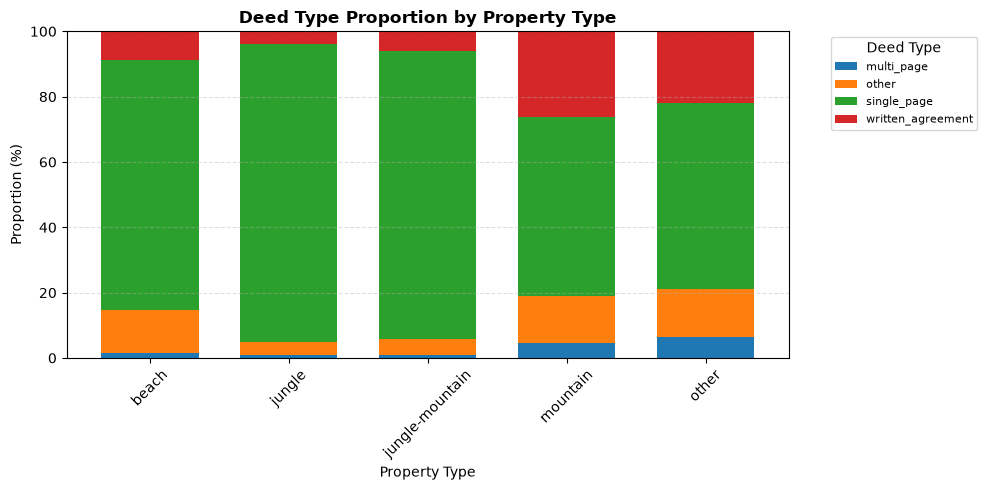

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

file_path = "C:/Users/Asus/Desktop/final_data.csv"
df = pd.read_csv(file_path,usecols=["property_type", "deed_type"])

print("Initial rows:", len(df))

df = df.dropna(subset=["property_type", "deed_type"])


print("Rows after removing missing values:",len(df))

# خلاصه نوع ملک
print("\nProperty types summary:")
print(df["property_type"].value_counts())


# خلاصه نوع سند
print("\nDeed types summary:")
print(df["deed_type"].value_counts())


# تشکیل جدول توافقی
contingency_table = pd.crosstab(
    df["property_type"],
    df["deed_type"])


print("\nContingency Table (Observed Frequencies):")

print(contingency_table)


# اجرای آزمون Chi-Square
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)

# بررسی شرط آزمون Chi-Square
cells_less_than_5 = np.sum(
    expected < 5)

total_cells = expected.size
pct_less_than_5 = (
    cells_less_than_5 /
    total_cells) * 100


print("\nChecking Chi-Square conditions:")

print(f"Total cells: {total_cells}")

print(f"Cells with expected count < 5: "
    f"{cells_less_than_5} "
    f"({pct_less_than_5:.1f}%)")


if (pct_less_than_5 <= 20
    and np.min(expected) > 0):
    print("\nConditions are met.")
    print("\nChi-Square Test of Independence")

    print("H0: property_type and deed_type are independent.")


    print("H1: property_type and deed_type are dependent.")

    print("Chi2 statistic:",chi2_stat)
    print("Degrees of freedom:",dof)

    print("p-value:",p_value)

    alpha = 0.05
    if p_value < alpha:
        print("\nReject H0")
        print("There is a significant relationship "
            "between property_type and deed_type.")


    else:
        print("\nFail to reject H0")
        print("There is no significant relationship "
            "between property_type and deed_type.")


else:
    print("\nConditions are not met.")


# درصد نوع سند به تفکیک نوع ملک
summary = (pd.crosstab(
        df["property_type"],
        df["deed_type"],
        normalize="index") * 100)


print("\nDeed type percentage distribution "
    "by property type:")

print(summary.round(2))


# نمودار
fig, ax = plt.subplots(figsize=(10, 5))


summary.plot(kind="bar",stacked=True,ax=ax,width=0.7)
ax.set_title("Deed Type Proportion by Property Type",fontsize=12,fontweight="bold")
ax.set_xlabel("Property Type",fontsize=10)
ax.set_ylabel("Proportion (%)",fontsize=10)
ax.set_ylim(0,100)
ax.tick_params(axis="x",rotation=45)
ax.legend(title="Deed Type",bbox_to_anchor=(1.05, 1),loc="upper left",fontsize=8)
ax.grid(axis="y",linestyle="--",alpha=0.4)

plt.tight_layout()
plt.show()